# Mô hình và baseline

Huấn luyện 3 thuật toán bằng walk-forward trên **một mã (TCB)** để xem từng bước. Số liệu chính thức của cả nhóm ở `docs/train.md`, tạo bằng `scripts/train_models.py`.

Chạy từ thư mục gốc repo, lần lượt từ trên xuống (khoảng 1 phút).

## 1. Ba thuật toán

| Thuật toán | Ý tưởng | Tối ưu gì | Siêu tham số chính |
|---|---|---|---|
| Logistic Regression | Tổ hợp tuyến tính các đặc trưng, đổi thành xác suất từng lớp | Cross-entropy (+ phạt L2) | `C`: nhỏ thì phạt mạnh |
| Random Forest | Nhiều cây quyết định học trên mẫu ngẫu nhiên, lấy trung bình | Mỗi cây giảm Gini | `n_estimators`, `max_depth`, `min_samples_leaf` |
| XGBoost | Cây thêm dần, mỗi cây sửa lỗi của các cây trước | Loss (log loss) bằng gradient | `learning_rate`, `max_depth`, `n_estimators` |

Baseline: **majority** (luôn đoán lớp phổ biến nhất) và **random** (đoán ngẫu nhiên theo tỷ lệ lớp của tập huấn luyện). SVM là gợi ý tùy chọn của đề, nhóm chưa làm.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SYMBOLS = ["TCB", "CTG", "VNM", "ACB"]
SYMBOL = "TCB"

from preprocess_data import feature_columns_for, walk_forward_splits
from train_models import CLASSES, RANDOM_STATE, build_models, score_fold
from sklearn.metrics import ConfusionMatrixDisplay, f1_score

data = pd.read_csv(ROOT / "data/processed/1D" / f"{SYMBOL}.csv")
features = list(feature_columns_for("1D"))
X, y = data[features].to_numpy(), data["label"].to_numpy() + 1
print(f"{len(data)} phiên, {len(features)} đặc trưng")
pd.Series(y).map({0: "giảm", 1: "ngang", 2: "tăng"}).value_counts(normalize=True).round(3)

2061 phiên, 25 đặc trưng


tăng     0.360
giảm     0.343
ngang    0.298
Name: proportion, dtype: float64

## 2. Walk-forward

Huấn luyện trên quá khứ, kiểm tra trên 63 phiên kế tiếp, bỏ 1 phiên giữa hai tập, rồi trượt tới. Không xáo trộn, nên không nhìn thấy tương lai.

20 fold, train từ 750 đến 1947 phiên, test 63 phiên


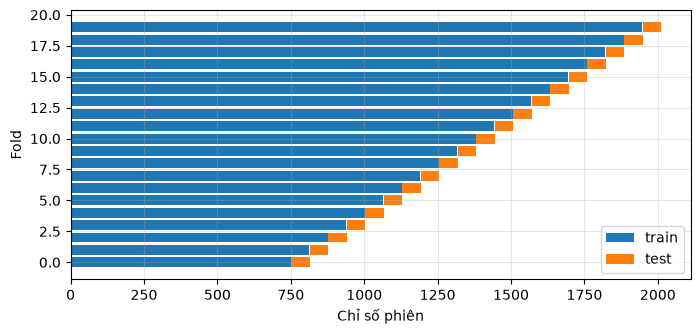

In [2]:
folds = list(walk_forward_splits(len(data), "1D"))
print(f"{len(folds)} fold, train từ {len(folds[0][0])} đến {len(folds[-1][0])} phiên, test 63 phiên")

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, (train, test) in enumerate(folds):
    ax.barh(i, len(train), color="tab:blue", label="train" if i == 0 else None)
    ax.barh(i, len(test), left=test[0], color="tab:orange", label="test" if i == 0 else None)
ax.set(xlabel="Chỉ số phiên", ylabel="Fold")
ax.legend()
plt.show()

## 3. Huấn luyện và đánh giá

Sửa `PARAMS` để đổi siêu tham số, ví dụ `"random_forest": {"max_depth": 5}`, `"logistic": {"model__C": 0.1}`, rồi chạy lại ô này và các ô sau.

In [3]:
PARAMS = {"logistic": {}, "random_forest": {}, "xgboost": {}}

rows, predictions = [], []
rng = np.random.default_rng(RANDOM_STATE)
for fold, (train, test) in enumerate(folds, start=1):
    prior = np.bincount(y[train], minlength=3) / len(train)
    rows.append({"fold": fold, "model": "random", **score_fold(y[test], rng.choice(CLASSES, size=len(test), p=prior), None)})
    for name, model in build_models().items():
        model.set_params(**PARAMS.get(name, {})).fit(X[train], y[train])
        proba = model.predict_proba(X[test])
        pred = CLASSES[proba.argmax(axis=1)]
        train_f1 = f1_score(y[train], model.predict(X[train]), average="macro")
        rows.append({"fold": fold, "model": name, **score_fold(y[test], pred, proba), "train_f1": train_f1})
        predictions.append(pd.DataFrame({"model": name, "y_true": y[test], "y_pred": pred}))

result = pd.DataFrame(rows)
order = ["majority", "random", "logistic", "random_forest", "xgboost"]
mean_std = lambda s: f"{s.mean():.3f} ± {s.std():.3f}"
result.groupby("model")[["accuracy", "f1_macro", "roc_auc", "train_f1"]].agg(mean_std).reindex(order)

,accuracy,f1_macro,roc_auc,train_f1
model,,,,
majority,0.345 ± 0.063,0.170 ± 0.024,0.500 ± 0.000,0.176 ± 0.001
random,0.333 ± 0.056,0.322 ± 0.057,nan ± nan,nan ± nan
logistic,0.363 ± 0.069,0.327 ± 0.055,0.521 ± 0.055,0.397 ± 0.008
random_forest,0.363 ± 0.057,0.339 ± 0.055,0.519 ± 0.058,1.000 ± 0.000
xgboost,0.341 ± 0.063,0.324 ± 0.063,0.498 ± 0.065,1.000 ± 0.000


**Nhận xét** (trung bình ± độ lệch chuẩn qua 20 fold):
- Mô hình chỉ hơn baseline một chút: F1 macro cao nhất 0,339 (Random Forest) so với 0,322 của đoán ngẫu nhiên; ROC-AUC từ 0,50 đến 0,52 (0,5 là đoán bừa). Độ lệch chuẩn giữa các fold (khoảng 0,06) lớn hơn khoảng cách giữa các mô hình, nên chưa thể nói mô hình nào tốt hơn.
- Majority có Accuracy 0,345 nhưng F1 chỉ 0,170 vì luôn đoán một lớp: đó là lý do dùng F1 macro.
- **Quá khớp:** Random Forest và XGBoost đạt F1 = 1,000 trên tập huấn luyện nhưng chỉ khoảng 0,33 trên tập test. Logistic ít quá khớp hơn (0,397 so với 0,327) nhưng cũng không dự đoán tốt hơn.

## 4. Phân tích lỗi

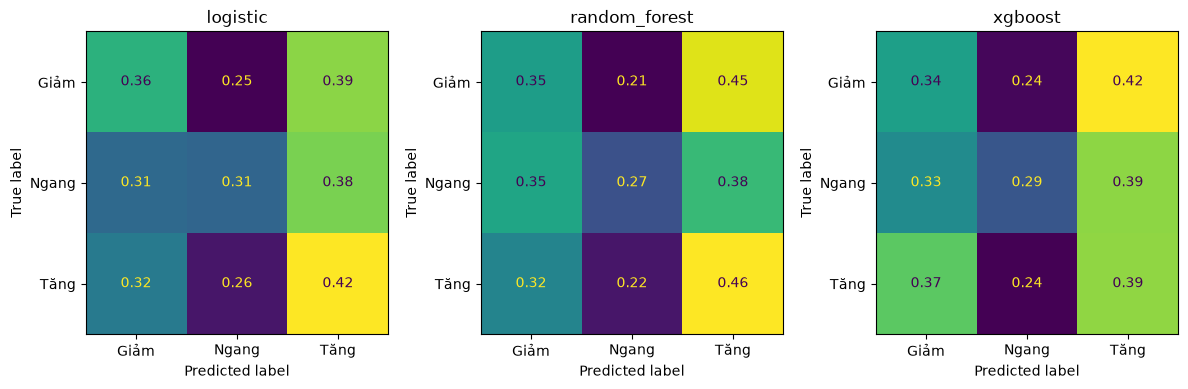

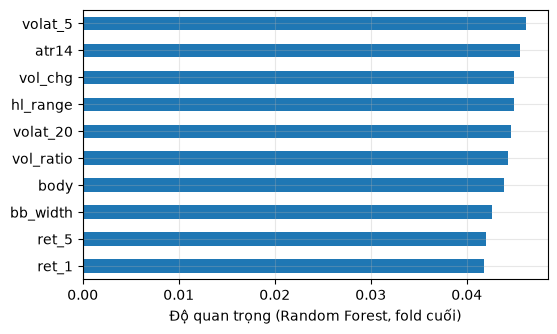

In [4]:
predictions = pd.concat(predictions)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name in zip(axes, order[2:]):
    frame = predictions[predictions.model == name]
    ConfusionMatrixDisplay.from_predictions(frame.y_true, frame.y_pred, display_labels=["Giảm", "Ngang", "Tăng"], normalize="true",
                                            ax=ax, colorbar=False, values_format=".2f")
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

importance = pd.Series(build_models()["random_forest"].fit(X[folds[-1][0]], y[folds[-1][0]]).feature_importances_, index=features)
importance.nlargest(10)[::-1].plot(kind="barh", figsize=(6, 3.5), xlabel="Độ quan trọng (Random Forest, fold cuối)")
plt.show()

**Nhận xét:**
- Cả ba mô hình đoán sai ở mọi lớp: ô đường chéo chỉ 0,27 đến 0,46 (đoán bừa là 0,33). Lớp "ngang" bị đoán đúng ít nhất (0,27 đến 0,31).
- Random Forest thiên về đoán "tăng": 45% phiên giảm bị đoán là tăng, vì lớp tăng nhiều nhất trong dữ liệu (36%).
- Độ quan trọng của 10 đặc trưng đầu gần như bằng nhau (0,042 đến 0,046; chia đều cho 25 đặc trưng là 0,04): không đặc trưng nào nổi bật, và nhóm đầu là biến động và khối lượng (`volat_5`, `atr14`, `vol_chg`), không phải đà giá.